# Sentinel-2 L2A radiometric offset: does it break a model trained on pre-2022 data?

**Claim being tested.** Since processing baseline 04.00 (25 January 2022), ESA's Level-2A products store surface reflectance with an added offset: `reflectance = (DN + BOA_ADD_OFFSET) / 10000` with `BOA_ADD_OFFSET = -1000`. Older products use `reflectance = DN / 10000`. A model trained on pre-2022 L2A data and fed post-2022 DNs unchanged therefore sees every pixel shifted by +1000.

**Sources for the offset**
- ESA, *Level-2A Algorithms and Products*: https://sentinel.esa.int/web/sentinel/technical-guides/sentinel-2-msi/level-2a-algorithms-products
- ESA STEP forum announcement, *Introduction of additional radiometric offset in PB04.00 products*: https://forum.step.esa.int/t/info-introduction-of-additional-radiometric-offset-in-pb04-00-products/35431
- Microsoft Planetary Computer, *baseline change* example: https://nbviewer.org/github/microsoft/PlanetaryComputerExamples/blob/main/datasets/sentinel-2-l2a/baseline-change.ipynb

**Experiment**
1. Take an openly available model trained only on pre-2022, offset-free L2A data.
2. Run it on a pre-2022 scene: predictions should be sensible.
3. Run it on a post-2022 scene of the same place and season, with the offset left in.
4. Run it again on that scene with the offset removed.

**Data sources matter.** Microsoft Planetary Computer serves ESA's original DNs (offset included after 2022). Element84 Earth Search v1 serves COGs with the offset **already removed**. We use Planetary Computer for the experiment and Earth Search as an independent check of the correction.

Runs on CPU or GPU. Packages: `torch`, `timm`, `rasterio`, `huggingface_hub`, `safetensors`, `requests`, `matplotlib`, `numpy`.

## Key terms

**Processing baseline.** The version of ESA's processing software and settings used to make a product. Every Sentinel-2 product records it in its metadata and name: `N0400` or `N0509` means baseline 04.00 or 05.09.

- ESA moved to baseline 04.00 on 25 January 2022. One of its changes added the +1000 offset.
- "Baseline ≥ 04.00" means any product made with version 04.00 or later (04.00, 05.00, 05.09, 05.10, …). All of them carry the offset.
- ESA has also reprocessed older images with newer baselines. A 2021 image can exist both as the original (03.00, no offset) and reprocessed (05.00, with offset). Check the baseline, not the acquisition date.

**DN (digital number).** The raw integer stored in the file for each pixel. Surface reflectance is the fraction of sunlight a surface reflects (0 to 1); ESA stores it as integers to save space.

| Baseline | Reflectance from DN | A surface reflecting 4.5% is stored as |
| --- | --- | --- |
| < 04.00 | DN / 10000 | 450 |
| ≥ 04.00 | (DN − 1000) / 10000 | 1450 |

The offset lets the files hold slightly negative reflectances, which atmospheric correction can produce over very dark surfaces. Without it they would be clipped to zero.

**Image display (DN/2500).** Display scaling only, used for the images in section 3. A screen needs brightness between 0 and 1, so each DN is divided by 2500 and capped at 1: 25% reflectance and above shows as full brightness. All images use the same scaling on purpose, so an image with the offset left in looks washed out. Every pixel is 1000 DN brighter, which pushes everything toward white.

In [1]:
import numpy as np
import requests
import torch
import timm
import rasterio
import matplotlib.pyplot as plt
from rasterio.enums import Resampling
from rasterio.warp import transform
from rasterio.windows import from_bounds
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

## 1. The model: BigEarthNet v2.0 ResNet-50 (Sentinel-2)

[`BIFOLD-BigEarthNetv2-0/resnet50-s2-v0.2.0`](https://huggingface.co/BIFOLD-BigEarthNetv2-0/resnet50-s2-v0.2.0) is a multi-label land-cover classifier (19 CORINE-based classes) trained on reBEN / BigEarthNet v2.0 ([Clasen et al., arXiv:2407.03653](https://arxiv.org/abs/2407.03653)). Its patches are Sentinel-2 L2A, 120×120 px at 10 m, acquired June 2017 – May 2018 over 10 European countries.

**Was its training data offset-free?** The training-set band means (from [`configilm/extra/BENv2_utils.py`](https://github.com/lhackel-tub/ConfigILM/blob/main/configilm/extra/BENv2_utils.py), `120_nearest`) answer that: the blue-band mean is 438 DN. Vegetated and urban blue reflectance is a few percent, so an offset-free mean of a few hundred is expected; with the offset it would be about 1438.

In [2]:
BANDS = ["B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B11", "B12"]

# BigEarthNet v2.0 training-set statistics, "120_nearest" variant
MEAN = np.array([438.3720703125, 614.0556640625, 588.4096069335938, 942.8433227539062, 1769.931640625,
                 2049.551513671875, 2193.2919921875, 2235.556640625, 1568.226806640625, 997.7324829101562], np.float32)
STD = np.array([607.02685546875, 603.2968139648438, 684.56884765625, 738.4326782226562, 1100.4560546875,
                1275.805419921875, 1369.3717041015625, 1356.5440673828125, 1070.1612548828125, 813.5276489257812], np.float32)

# Output order is lexicographic (configilm's default lex_sorted=True)
LABELS = sorted([
    "Urban fabric", "Industrial or commercial units", "Arable land", "Permanent crops", "Pastures",
    "Complex cultivation patterns",
    "Land principally occupied by agriculture, with significant areas of natural vegetation",
    "Agro-forestry areas", "Broad-leaved forest", "Coniferous forest", "Mixed forest",
    "Natural grassland and sparsely vegetated areas", "Moors, heathland and sclerophyllous vegetation",
    "Transitional woodland, shrub", "Beaches, dunes, sands", "Inland wetlands", "Coastal wetlands",
    "Inland waters", "Marine waters",
])

for b, m in zip(BANDS, MEAN):
    print(f"{b}: training mean {m:7.1f} DN")

B02: training mean   438.4 DN
B03: training mean   614.1 DN
B04: training mean   588.4 DN
B05: training mean   942.8 DN
B06: training mean  1769.9 DN
B07: training mean  2049.6 DN
B08: training mean  2193.3 DN
B8A: training mean  2235.6 DN
B11: training mean  1568.2 DN
B12: training mean   997.7 DN


The published weights are a plain timm ResNet-50 with 10 input channels inside a ConfigILM wrapper. We strip the wrapper prefix and load them strictly into timm, so no training framework is needed.

In [3]:
weights = hf_hub_download("BIFOLD-BigEarthNetv2-0/resnet50-s2-v0.2.0", "model.safetensors")
state = {k.removeprefix("model.vision_encoder."): v for k, v in load_file(weights).items()}
model = timm.create_model("resnet50", pretrained=False, in_chans=10, num_classes=19)
model.load_state_dict(state, strict=True)
model = model.eval().to(device)


@torch.no_grad()
def predict(dn, size=120):
    """Split a [10, H, W] DN array into 120x120 patches and return per-patch class probabilities."""
    x = (dn - MEAN[:, None, None]) / STD[:, None, None]
    c, h, w = x.shape
    gh, gw = h // size, w // size
    patches = x[:, : gh * size, : gw * size].reshape(c, gh, size, gw, size).transpose(1, 3, 0, 2, 4).reshape(-1, c, size, size)
    probs = torch.sigmoid(model(torch.from_numpy(np.ascontiguousarray(patches)).to(device))).cpu().numpy()
    return probs, (gh, gw)

## 2. The data: one place, same day of year, before and after the baseline change

Area: 12 × 12 km around Coimbra, Portugal (100 patches): city, forest and farmland. Portugal is one of the BigEarthNet countries, so the model is in its home domain. Both acquisitions are Sentinel-2B, relative orbit 37, tile 29TNE, 28 July, nearly cloud-free.

| Scene | Processing baseline | Offset in stored DN |
| --- | --- | --- |
| 2021-07-28 | 03.00 | none |
| 2023-07-28 | 05.09 | +1000 |

In [4]:
PC_STAC = "https://planetarycomputer.microsoft.com/api/stac/v1"
ES_STAC = "https://earth-search.aws.element84.com/v1"
ES_KEY = {"B02": "blue", "B03": "green", "B04": "red", "B05": "rededge1", "B06": "rededge2",
          "B07": "rededge3", "B08": "nir", "B8A": "nir08", "B11": "swir16", "B12": "swir22"}

# 12 x 12 km box in UTM 29N, aligned to the 120 m patch grid
x, y = transform("EPSG:4326", "EPSG:32629", [-8.43], [40.205])
x0, y0 = int(x[0]) // 120 * 120 - 6000, int(y[0]) // 120 * 120 - 6000
BOUNDS = (x0, y0, x0 + 12000, y0 + 12000)


def read_dn(hrefs, bounds=BOUNDS):
    """Read the 10 bands as stored (no rescaling, no offset handling) at 10 m; 20 m bands nearest-upsampled."""
    h, w = int((bounds[3] - bounds[1]) / 10), int((bounds[2] - bounds[0]) / 10)
    out = []
    for href in hrefs:
        with rasterio.open(href) as src:
            win = from_bounds(*bounds, transform=src.transform)
            out.append(src.read(1, window=win, out_shape=(h, w), resampling=Resampling.nearest))
    return np.stack(out).astype(np.float32)


def pc_item(date):
    r = requests.post(f"{PC_STAC}/search", timeout=60, json={
        "collections": ["sentinel-2-l2a"], "bbox": [-8.44, 40.20, -8.42, 40.21],
        "datetime": f"{date}T00:00:00Z/{date}T23:59:59Z"}).json()
    # Planetary Computer can list reprocessed duplicates; keep the earliest-produced (original) product
    return sorted(r["features"], key=lambda f: f["id"])[0]


token = requests.get("https://planetarycomputer.microsoft.com/api/sas/v1/token/sentinel-2-l2a", timeout=60).json()["token"]
items = {d: pc_item(d) for d in ["2021-07-28", "2023-07-28"]}
dn = {}
for d, it in items.items():
    pb = it["properties"]["s2:processing_baseline"]
    dn[d] = read_dn([it["assets"][b]["href"] + "?" + token for b in BANDS])
    print(f"{d}  {it['id']}  baseline {pb}  ->  offset {'+1000' if float(pb) >= 4 else 'none'}")

2021-07-28  S2B_MSIL2A_20210728T112119_R037_T29TNE_20210729T015306  baseline 03.00  ->  offset none


2023-07-28  S2B_MSIL2A_20230728T112119_R037_T29TNE_20230728T151853  baseline 05.09  ->  offset +1000


### 2a. The offset is visible in the raw values

Same place, same season, two years apart. Real surfaces change a little; a +1000 jump in every band does not happen naturally. The darkest pixels make it obvious: an offset-free scene goes down to near zero, an offset scene cannot go below about 1000.

2021-07-28:  B02 1st percentile    191   median per band: {'B02': 446, 'B04': 649, 'B08': 2946, 'B12': 1403}
2023-07-28:  B02 1st percentile   1107   median per band: {'B02': 1380, 'B04': 1594, 'B08': 3866, 'B12': 2395}


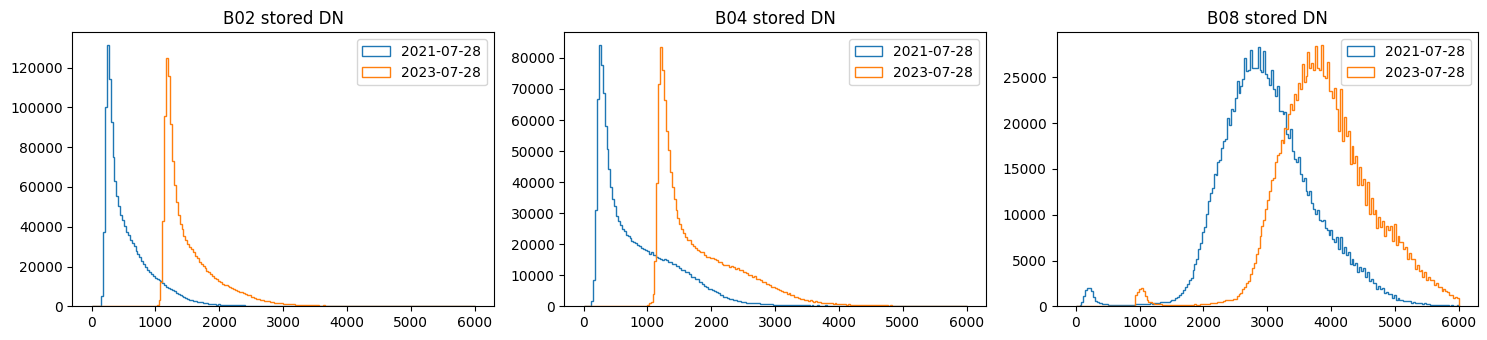

In [5]:
for d, a in dn.items():
    valid = a[0] > 0
    print(f"{d}:  B02 1st percentile {np.percentile(a[0][valid], 1):6.0f}   median per band:",
          {b: int(np.median(a[i][valid])) for i, b in enumerate(BANDS) if b in ("B02", "B04", "B08", "B12")})

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for i, b in enumerate(["B02", "B04", "B08"]):
    k = BANDS.index(b)
    for d, a in dn.items():
        ax[i].hist(a[k].ravel(), bins=200, range=(0, 6000), histtype="step", label=d)
    ax[i].set_title(f"{b} stored DN")
    ax[i].legend()
plt.tight_layout()

### 2b. Removing the offset

Following ESA's formula, subtract 1000 for baseline ≥ 04.00 products and keep nodata (0) as 0. As an independent check, Earth Search v1 publishes the same 2023 acquisition with the offset already removed; our corrected array should match it to within a few tens of DN (small differences come from separate product generation), far below the 1000 DN offset.

In [6]:
def remove_offset(a, boa_add_offset=-1000):
    nodata = a == 0
    out = np.clip(a + boa_add_offset, 0, None)
    out[nodata] = 0
    return out


dn["2023-07-28 offset removed"] = remove_offset(dn["2023-07-28"])

es = requests.get(f"{ES_STAC}/collections/sentinel-2-l2a/items/S2B_29TNE_20230728_0_L2A", timeout=60).json()
es_dn = read_dn([es["assets"][ES_KEY[b]]["href"] for b in BANDS])
diff = np.abs(es_dn - dn["2023-07-28 offset removed"])
print("Earth Search (pre-corrected) vs our correction: median |diff| per band =", np.median(diff.reshape(10, -1), axis=1))

Earth Search (pre-corrected) vs our correction: median |diff| per band = [ 6.  8.  7. 12. 23. 28. 32. 30. 22. 13.]


## 3. Model predictions

The 2021 scene is the in-distribution case: offset-free data, like the training set. We use its predictions as the reference. A landscape this stable should get mostly the same labels two years later, apart from some genuine change (crops, construction, fire).

In [7]:
preds = {}
for k, a in dn.items():
    preds[k], grid = predict(a)

ref = preds["2021-07-28"]
print(f"{'input':28s} {'label-set agreement':>20s} {'identical labels':>17s} {'mean |dp|':>10s}")
for k, p in preds.items():
    lab, rlab = p >= 0.5, ref >= 0.5
    union = (lab | rlab).sum(1)
    jaccard = np.where(union > 0, (lab & rlab).sum(1) / np.maximum(union, 1), 1.0).mean()
    print(f"{k:28s} {jaccard:20.2f} {np.mean((lab == rlab).all(1)):17.2f} {np.abs(p - ref).mean():10.3f}")

input                         label-set agreement  identical labels  mean |dp|
2021-07-28                                   1.00              1.00      0.000
2023-07-28                                   0.24              0.04      0.163
2023-07-28 offset removed                    0.81              0.36      0.045


*Label-set agreement*: mean Jaccard overlap between each patch's predicted labels (probability ≥ 0.5) and the 2021 labels. *Identical labels*: share of patches with exactly the same label set.

### 3a. What the model predicts, per input

In [8]:
def label_counts(p):
    return {LABELS[i]: int(n) for i, n in enumerate((p >= 0.5).sum(0)) if n > 0}

for k, p in preds.items():
    top = sorted(label_counts(p).items(), key=lambda kv: -kv[1])[:5]
    print(f"{k}:")
    for name, n in top:
        print(f"    {n:3d} patches  {name}")

2021-07-28:
     74 patches  Land principally occupied by agriculture, with significant areas of natural vegetation
     74 patches  Urban fabric
     68 patches  Complex cultivation patterns
     61 patches  Mixed forest
     38 patches  Transitional woodland, shrub
2023-07-28:
     35 patches  Urban fabric
     26 patches  Industrial or commercial units
     22 patches  Arable land
     20 patches  Complex cultivation patterns
      7 patches  Coniferous forest
2023-07-28 offset removed:
     73 patches  Urban fabric
     68 patches  Mixed forest
     65 patches  Land principally occupied by agriculture, with significant areas of natural vegetation
     58 patches  Complex cultivation patterns
     35 patches  Broad-leaved forest


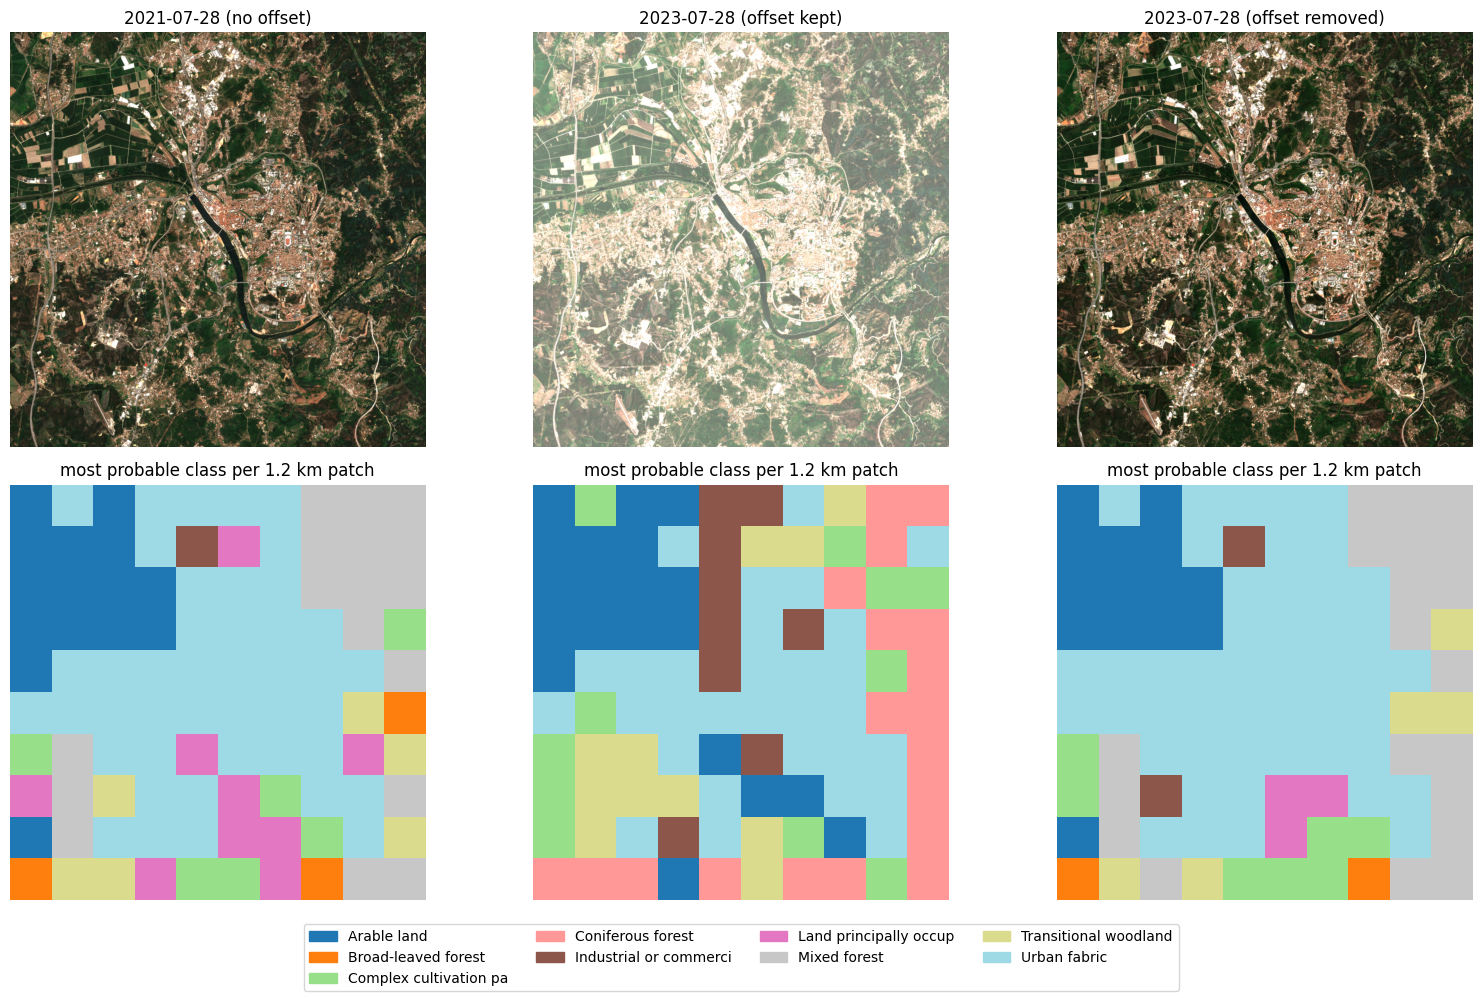

In [9]:
def rgb(a):
    x = a[[2, 1, 0]].transpose(1, 2, 0)
    return np.clip(x / 2500, 0, 1)


TITLES = {"2021-07-28": "2021-07-28 (no offset)", "2023-07-28": "2023-07-28 (offset kept)",
          "2023-07-28 offset removed": "2023-07-28 (offset removed)"}
short = {n: n.split(",")[0][:22] for n in LABELS}
classes = sorted({int(i) for p in preds.values() for i in p.argmax(1)})
cmap = plt.get_cmap("tab20", len(classes))

fig, ax = plt.subplots(2, 3, figsize=(16, 10))
for j, k in enumerate(preds):
    ax[0, j].imshow(rgb(dn[k]))
    ax[0, j].set_title(TITLES[k])
    top = np.vectorize(classes.index)(preds[k].argmax(1)).reshape(grid)
    ax[1, j].imshow(top, cmap=cmap, vmin=-0.5, vmax=len(classes) - 0.5)
    ax[1, j].set_title("most probable class per 1.2 km patch")
for a in ax.ravel():
    a.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=cmap(i)) for i in range(len(classes))]
fig.legend(handles, [short[LABELS[c]] for c in classes], loc="lower center", ncol=4)
plt.tight_layout(rect=(0, 0.08, 1, 1))

## 4. The dependable fix: harmonize when you load the data

**Harmonizing** means converting every product to one value convention before anything else touches it: before computing statistics, before training, before inference. The usual choice is the pre-04.00 convention, `reflectance = DN / 10000`, because most archives and pretrained models use it. ([Google Earth Engine's `S2_SR_HARMONIZED`](https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S2_SR_HARMONIZED) and Earth Search v1 make the same choice.)

Decide **per product, from its metadata**, never from the date:

1. **Did the provider already harmonize it?** Earth Search v1 marks this with `earthsearch:boa_offset_applied: True`. Do nothing, or you shift the data a second time.
2. **Otherwise, check the processing baseline.** If it is ≥ 04.00, subtract the offset. ESA states it per band as `BOA_ADD_OFFSET` in the product metadata (`MTD_MSIL2A.xml`); it is −1000 for all bands so far.
3. **Keep nodata as nodata.** The value 0 means "no data" in both conventions and must stay 0.
4. **Decide what to do with values that become negative.** Very dark pixels (deep water, shadow) can drop below 0 after subtraction. Here they are clipped to 0. Keeping them as small negative values is also defensible; choose one and use it in training and inference alike.

Do it in the one function that reads imagery, so no path can skip it. The same function serves training data preparation and the live pipeline.

In [10]:
def harmonize(dn, item):
    """Convert stored DN to the pre-04.00 convention (reflectance = DN / 10000), deciding from item metadata."""
    props = item["properties"]
    if props.get("earthsearch:boa_offset_applied"):
        return dn, "provider already removed the offset"
    baseline = props.get("s2:processing_baseline")
    if baseline is None:
        raise ValueError(f"{item['id']}: no processing baseline in metadata; cannot decide")
    if float(baseline) < 4.0:
        return dn, f"baseline {baseline}: no offset"
    return remove_offset(dn, boa_add_offset=-1000), f"baseline {baseline}: offset removed"


sources = {
    "Planetary Computer 2021-07-28": (dn["2021-07-28"], items["2021-07-28"]),
    "Planetary Computer 2023-07-28": (dn["2023-07-28"], items["2023-07-28"]),
    "Earth Search 2023-07-28": (es_dn, es),
}
print(f"{'source':32s} {'decision':38s} {'B02 median before':>18s} {'after':>6s}")
for name, (a, item) in sources.items():
    h, decision = harmonize(a, item)
    print(f"{name:32s} {decision:38s} {np.median(a[0][a[0] > 0]):18.0f} {np.median(h[0][h[0] > 0]):6.0f}")

source                           decision                                B02 median before  after
Planetary Computer 2021-07-28    baseline 03.00: no offset                             446    446
Planetary Computer 2023-07-28    baseline 05.09: offset removed                       1380    380
Earth Search 2023-07-28          provider already removed the offset                   380    380


After harmonizing, all three sources sit on the same convention (blue median in the few-hundreds range), whichever provider or baseline they came from. The Earth Search product is left untouched, which is correct here: subtracting 1000 again would break the model as badly as leaving the offset in.

## 5. Conclusions

Read the numbers above before relying on these statements.

- **Offset source.** Products from processing baseline ≥ 04.00 store DN with a +1000 offset (ESA, linked above). It is visible directly in the raw values (section 2a).
- **Normalisation does not absorb it.** The model normalises with fixed training means and standard deviations, so +1000 DN becomes a band-dependent shift of roughly 0.7 to 1.6 standard deviations (1000 / std per band).
- **Effect.** Compare the agreement table: offset data against offset-removed data, both against the 2021 reference.
- **Fix.** Harmonize every product to one convention when loading it, deciding from its own metadata (section 4). Subtracting `BOA_ADD_OFFSET` restores the input convention and agrees with Earth Search's pre-corrected product to within a few tens of DN (section 2b).
- **Where your data comes from decides whether you must correct.** Planetary Computer and ESA/CDSE SAFE files carry the offset. Earth Search v1 COGs have it removed already, and Google Earth Engine offers a separately harmonised collection. Correcting data that is already corrected shifts it by −1000 and breaks the model just as badly.

**Limitations.** One area, two dates, one model, and no ground-truth labels: agreement is measured against the model's own 2021 predictions, so some disagreement is real land-cover change. To tighten it, add more tiles and dates, or score against CORINE Land Cover.